In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, Sequential


from src.datasets import create_datasets, class_names
from src.ViT_model_definitions import build_small_vit, build_hybrid_model

2026-10-13 08:25:52.759354: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 08:25:52.775961: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 08:25:52.781069: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1791879953.938391    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791879953.946071    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791879953.947941    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


### 01. Hyperparameters and dataset setup

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 30  # Change as needed.


models_path = Path("models")

In [4]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1791879954.199516    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791879954.204246    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791879954.211811    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791879954.333861    3660 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


### 02. Create the ViT model

In [5]:
vit_model = build_small_vit(
    image_size=IMG_SIZE,
    patch_size=8,
    embed_dim=64,
    num_heads=4,
    mlp_dim=128,
    num_transformer_layers=2,
    dropout=0.1,
    num_classes=len(class_names)
)

vit_model.summary()

Model: "small_vit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_embedding                 │ (None, 64, 64)         │        12,352 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 64, 64)         │         4,096 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,522 (326.26 KB)

 Trainable params: 83,522 (326.26 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 03. Train the pure ViT model

In [7]:
# Create the ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(filepath=models_path / "ai_capstone_keras_pure_vit_model.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [8]:
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    callbacks=[checkpoint_cb],
    epochs=EPOCHS
)

Epoch 1/30


I0000 00:00:1791879958.775736    3741 service.cc:146] XLA service 0x73c46c00a210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791879958.775760    3741 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 13/132 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5019 - loss: 1.5984

I0000 00:00:1791879965.254310    3741 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5751 - loss: 0.8919
Epoch 1: val_loss improved from inf to 0.31791, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - accuracy: 0.5759 - loss: 0.8898 - val_accuracy: 0.8678 - val_loss: 0.3179
Epoch 2/30
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8627 - loss: 0.3098
Epoch 2: val_loss improved from 0.31791 to 0.26576, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8630 - loss: 0.3091 - val_accuracy: 0.8811 - val_loss: 0.2658
Epoch 3/30
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9221 - loss: 0.1834
Epoch 3: val_loss improved from 0.26576 to 0.13736, saving model to models/ai_capstone_keras_pure_vit_model.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9224 - loss: 0.1827 - val_accuracy: 0.9511 - val_loss: 0.1374
Epoch 4/30
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - ac

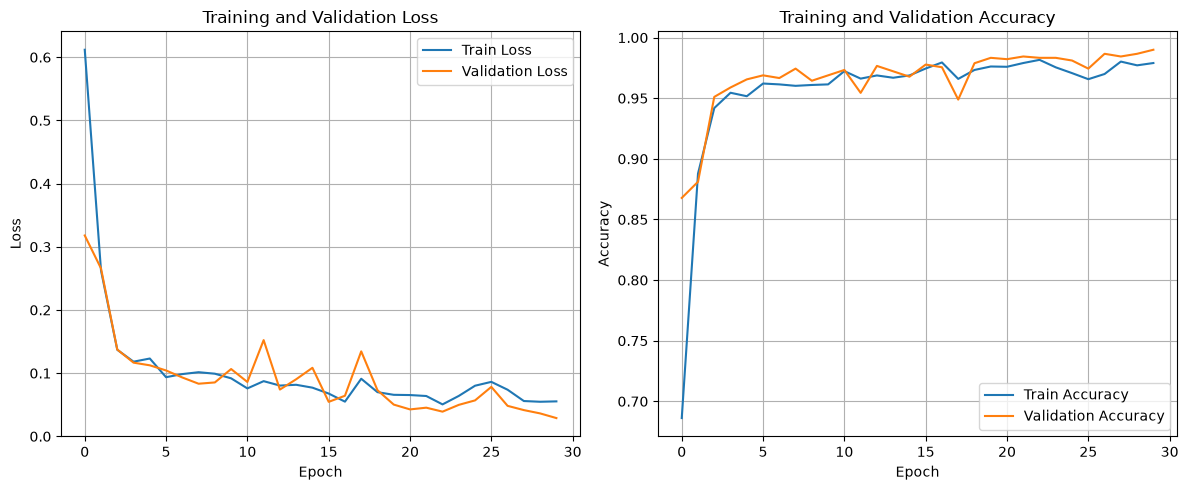

In [9]:
# Plot loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vit.history["loss"], label="Train Loss")
plt.plot(history_vit.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history_vit.history["accuracy"], label="Train Accuracy")
plt.plot(history_vit.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
vit_model = tf.keras.models.load_model( models_path / "ai_capstone_keras_pure_vit_model.keras")


/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'transformer_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'transformer_block_1', however t

In [11]:

# Get class names

misclassified_images = []
misclassified_true = []
misclassified_pred = []
misclassified_conf = []

# Go through the entire test set
for images, labels in test_ds:
    predictions = vit_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)

    for i in range(len(images)):
        if predicted_classes[i] != labels[i].numpy():
            misclassified_images.append(images[i].numpy())
            misclassified_true.append(labels[i].numpy())
            misclassified_pred.append(predicted_classes[i])
            misclassified_conf.append(confidences[i])

print(f"Misclassified images: {len(misclassified_images)}")

Misclassified images: 9


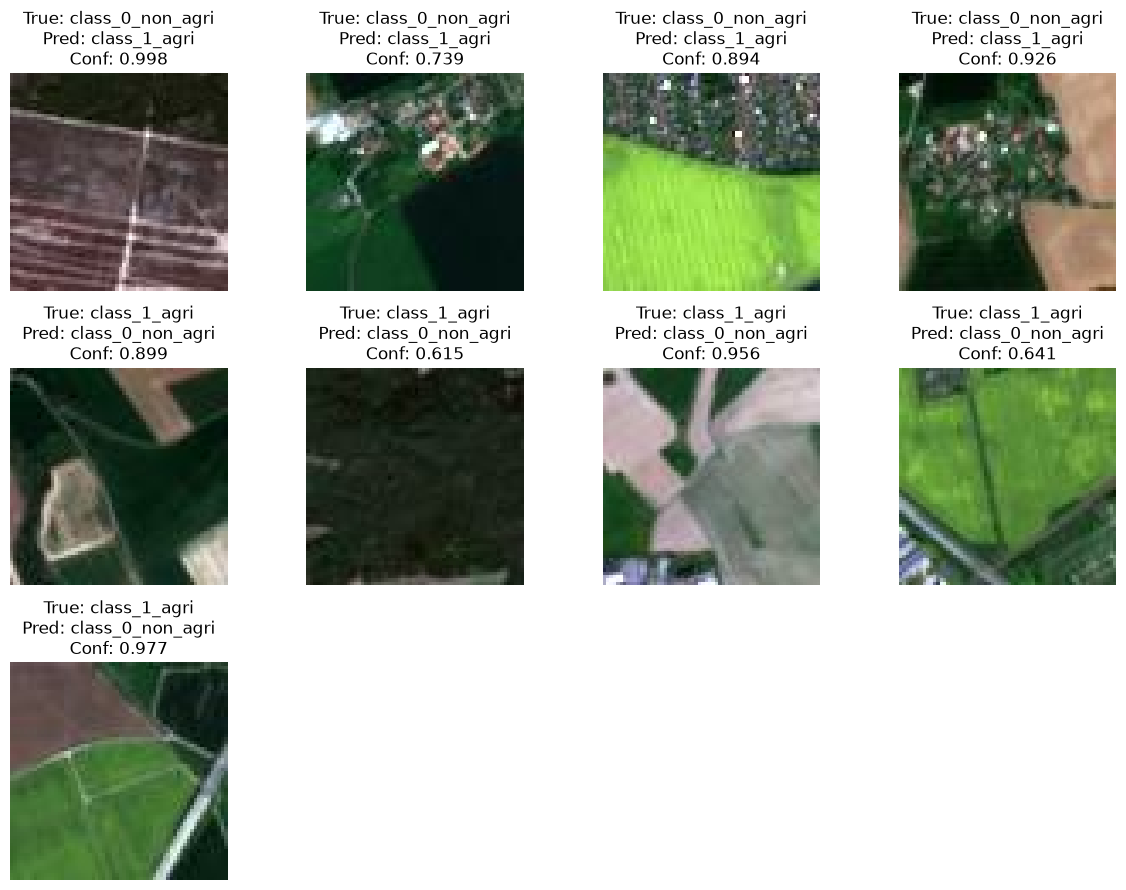

In [12]:
import math

n = len(misclassified_images)

if n == 0:
    print("No misclassified images!")
else:
    cols = min(4, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(12, 3 * rows))

    for i in range(n):
        ax = plt.subplot(rows, cols, i + 1)

        # Convert 0–255 float32 -> uint8
        image = np.clip(misclassified_images[i], 0, 255).astype(np.uint8)

        plt.imshow(image)

        plt.title(
            f"True: {class_names[misclassified_true[i]]}\n"
            f"Pred: {class_names[misclassified_pred[i]]}\n"
            f"Conf: {misclassified_conf[i]:.3f}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

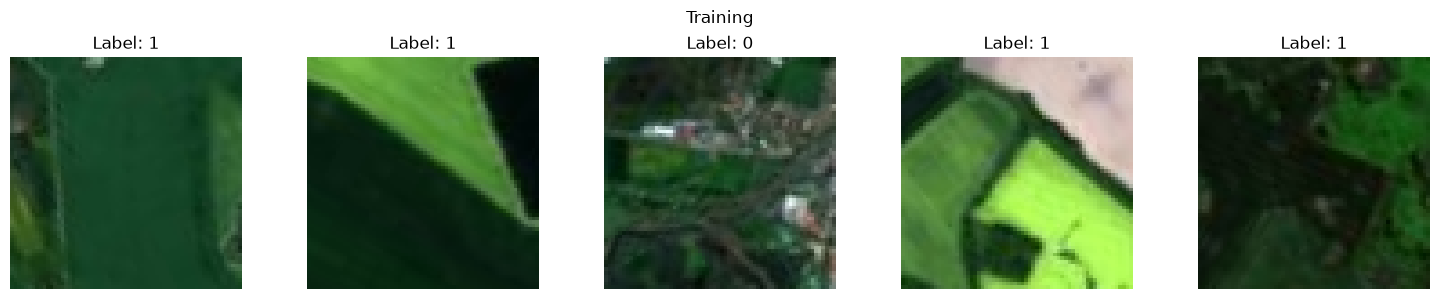

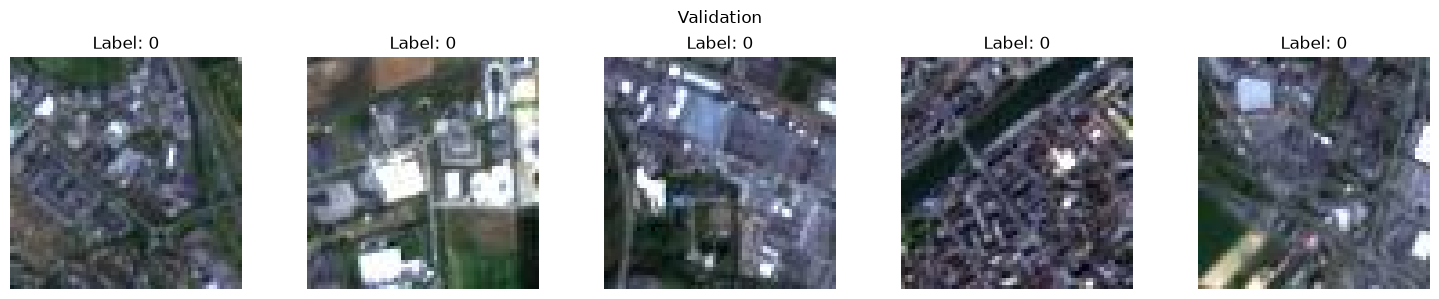

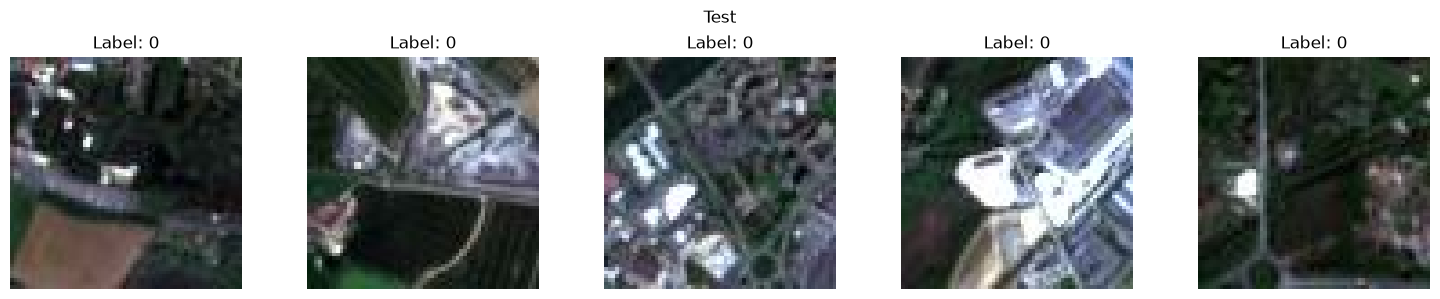

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def unnormalize_image(image):
    image = np.asarray(image, dtype=np.float32)

    # If normalized to [0, 1], convert back to [0, 255].
    if image.min() >= 0 and image.max() <= 1:
        image = image * 255.0

    # Convert 0–255 float32 -> uint8
    image = np.clip(image, 0, 255).astype(np.uint8)

    return image


def show_first_five(dataset, name):
    plt.figure(figsize=(15, 3))

    images_shown = 0

    for images, labels in dataset.take(1):
        n = min(5, images.shape[0])

        for i in range(n):
            image = unnormalize_image(images[i].numpy())
            label = labels[i].numpy()

            plt.subplot(1, 5, i + 1)
            plt.imshow(image)
            plt.title(f"Label: {label}")
            plt.axis("off")

            images_shown += 1

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()


# Replace names if your datasets use different variable names.
show_first_five(train_ds, "Training")
show_first_five(val_ds, "Validation")
show_first_five(test_ds, "Test")